In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress, norm, percentileofscore, fisher_exact
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import pyreadr
import statistics as stats
import math
from tabulate import tabulate
from statsmodels.stats.contingency_tables import mcnemar
import matplotlib.patches as patches
import pyBigWig
import re

In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)

comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)
basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)

1
1


In [3]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [4]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [6]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
n_biosamples, n_DHSs = cycle0_dhs_arr.shape

In [7]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/max_DHS_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220322.npy'
DHS_max_signal_array = np.load(file)

In [8]:
#load npz file
added_recon_all_cycles = []
removed_recon_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 2):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_added_removed_recon_flatinds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    added_recon_all_cycles.append(cycle_np_file['added_recon'])
    removed_recon_all_cycles.append(cycle_np_file['removed_recon'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [9]:
added_DHS_inds = added_flat_inds_all_cycles[0]%n_DHSs
added_biosample_inds = added_flat_inds_all_cycles[0]//n_DHSs

In [10]:
added_DHS_identifiers = np.array(DHS_metadata.loc[added_DHS_inds]['identifier'])

In [11]:
#lns for added biosamples
added_biosample_ln = np.array(biosample_df.loc[added_biosample_inds]['Altius Library ID'])
added_biosample_ln_stripped = np.array([])
for ln in added_biosample_ln:
    if ln[-1].isalpha():
        added_biosample_ln_stripped = np.append(added_biosample_ln_stripped, ln[:-1])
    else:
        added_biosample_ln_stripped = np.append(added_biosample_ln_stripped, ln)

In [75]:
#signal percentile analysis
added_call_max_signal_percentiles = []
added_DHS_all_call_max_signal_percentiles = []
used_DHS_inds = set([])
for i in range(len(added_biosample_inds)):
    biosample_ind = added_biosample_inds[i]
    DHS_ind = added_DHS_inds[i]
    added_max_signal = DHS_max_signal_array[biosample_ind, DHS_ind]
    kp_biosamples = np.arange(n_biosamples)[cycle0_dhs_arr[:, DHS_ind]]
    kp_max_signals = DHS_max_signal_array[kp_biosamples, DHS_ind]
    added_call_max_signal_percentiles.append(percentileofscore(kp_max_signals, added_max_signal))
    if DHS_ind not in used_DHS_inds:
        used_DHS_inds.add(DHS_ind)
        for signal in kp_max_signals:
            added_DHS_all_call_max_signal_percentiles.append(percentileofscore(kp_max_signals, signal))
added_call_max_signal_percentiles = np.array(added_call_max_signal_percentiles)
added_DHS_all_call_max_signal_percentiles = np.array(added_DHS_all_call_max_signal_percentiles)

Max Signal Percentile for Added Calls


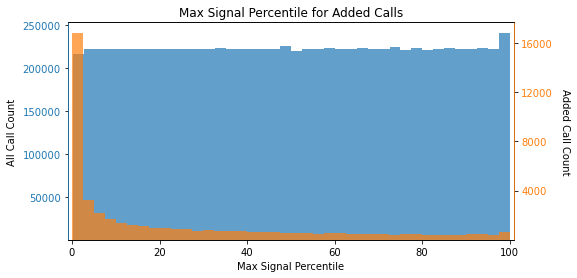

In [78]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(8,4))
fig.patch.set_facecolor('white')

axes.hist(added_DHS_all_call_max_signal_percentiles, bins=40, alpha=0.7)
axes.set_xlim([-1, 101])
ax_twin = axes.twinx()
ax_twin.hist(added_call_max_signal_percentiles, color='#ff7f0e', bins=40, alpha=0.7)
axes.set_xlabel('Max Signal Percentile')

axes_ticks = [50000, 100000, 150000, 200000, 250000]
axes.set_yticks(axes_ticks)
axes.set_yticklabels(axes_ticks, c='#1f77b4')
twin_ticks = [4000, 8000, 12000, 16000]
ax_twin.set_yticks(twin_ticks)
ax_twin.set_yticklabels(twin_ticks, c='#ff7f0e')
fig.text(0.02, 0.5, 'All Call Count', va='center', rotation=90, fontsize=10)
fig.text(0.98, 0.5, 'Added Call Count', va='center', rotation=270, fontsize=10)
ax_twin.spines['left'].set_color('#1f77b4')
ax_twin.spines['right'].set_color('#ff7f0e')
title = 'Max Signal Percentile for Added Calls'
plt.title(title)
today = date.today()
plt.savefig('/home/ctrader/figures/NMF/DHS/quality_of_NMF_recon_threshold_flip_01thresh_peak_added_analysis/'+title.replace(' ', '_') + '_CT' + today.strftime("%Y%m%d") + '.png')
print(title)

array([1.931603 , 1.8393092, 1.7957729, ..., 1.000005 , 1.000005 ,
       1.0000005], dtype=float32)

0.03304645169273241


Text(0.5, 1.0, 'Max Signal Percentile with Reconstruction Values')

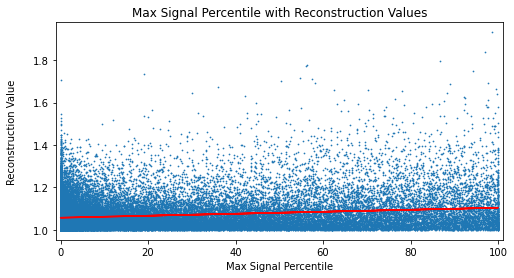

In [96]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(8,4))
fig.patch.set_facecolor('white')

# m, b = np.polyfit(added_call_max_signal_percentiles, added_recon_all_cycles[0], 1)
m, b, r, p, e = linregress(added_call_max_signal_percentiles, added_recon_all_cycles[0])

axes.scatter(added_call_max_signal_percentiles, added_recon_all_cycles[0], s=0.5)
axes.plot(added_call_max_signal_percentiles, m*added_call_max_signal_percentiles+b, c='r')
axes.set_xlim([-1, 101])
axes.set_xlabel('Max Signal Percentile')

print(r**2)

fig.text(0.04, 0.5, 'Reconstruction Value', va='center', rotation=90, fontsize=10)
title = 'Max Signal Percentile with Reconstruction Values'
plt.title(title)
# today = date.today()
# plt.savefig('/home/ctrader/figures/NMF/DHS/quality_of_NMF_recon_threshold_flip_01thresh_peak_added_analysis/'+title.replace(' ', '_') + '_CT' + today.strftime("%Y%m%d") + '.png')
# print(title)

Signal of Added Biosample in DHS 2.9359766
Compared to Signal of Top 5 Positive Call Biosamples


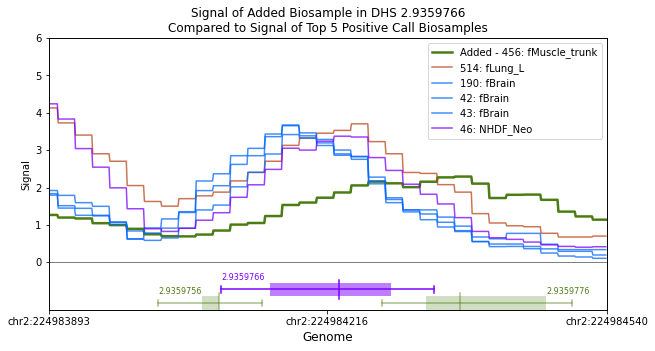

Signal of Added Biosample in DHS 10.409564
Compared to Signal of Top 5 Positive Call Biosamples


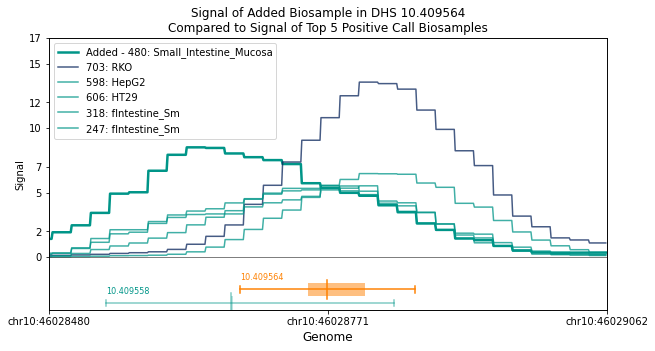

Signal of Added Biosample in DHS 8.925174
Compared to Signal of Top 5 Positive Call Biosamples


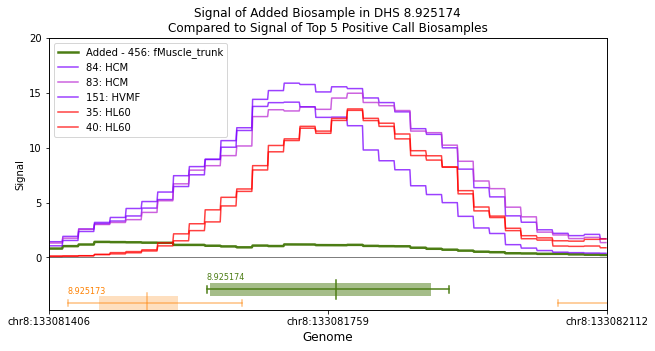

Signal of Added Biosample in DHS 5.428305
Compared to Signal of Top 5 Positive Call Biosamples


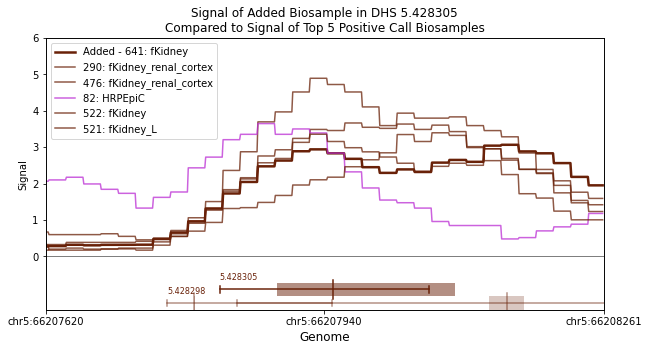

Signal of Added Biosample in DHS 2.916572
Compared to Signal of Top 5 Positive Call Biosamples


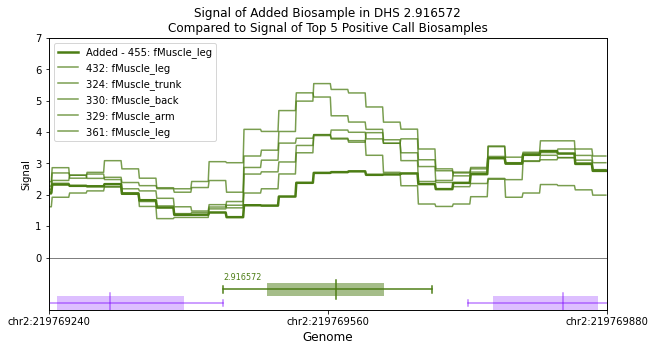

Signal of Added Biosample in DHS 1.929849
Compared to Signal of Top 5 Positive Call Biosamples


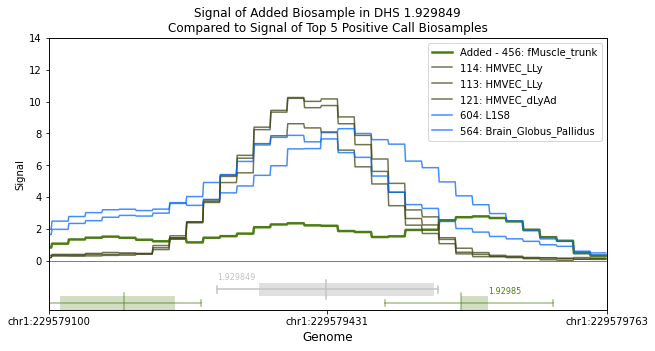

Signal of Added Biosample in DHS 19.73768
Compared to Signal of Top 5 Positive Call Biosamples


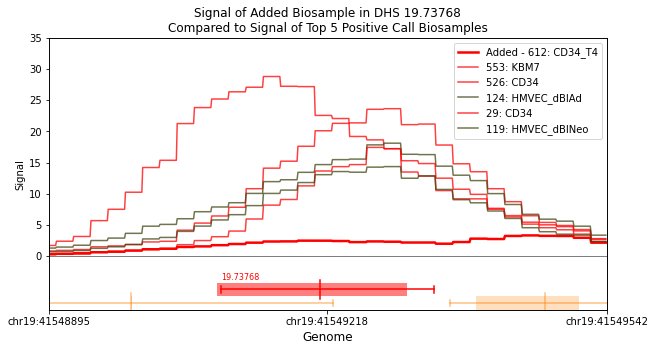

Signal of Added Biosample in DHS 15.7886646
Compared to Signal of Top 5 Positive Call Biosamples


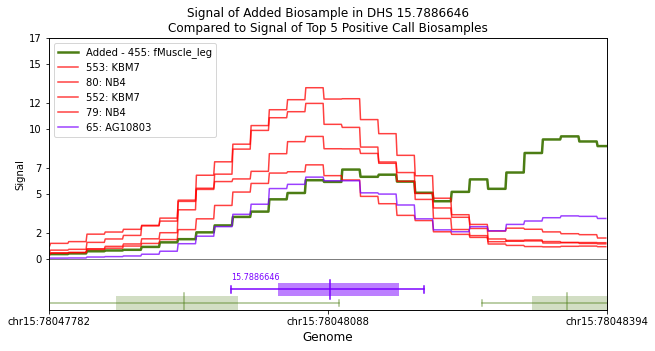

Signal of Added Biosample in DHS 1.352661
Compared to Signal of Top 5 Positive Call Biosamples


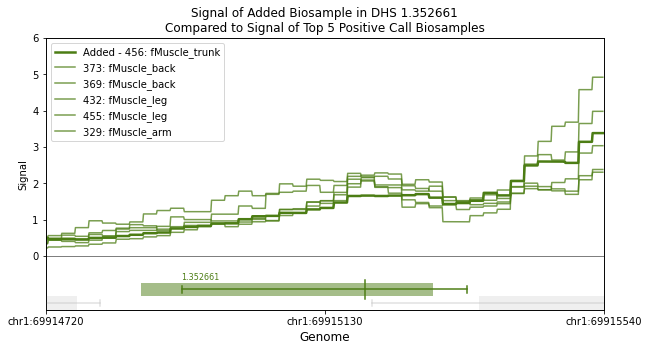

Signal of Added Biosample in DHS 16.350631
Compared to Signal of Top 5 Positive Call Biosamples


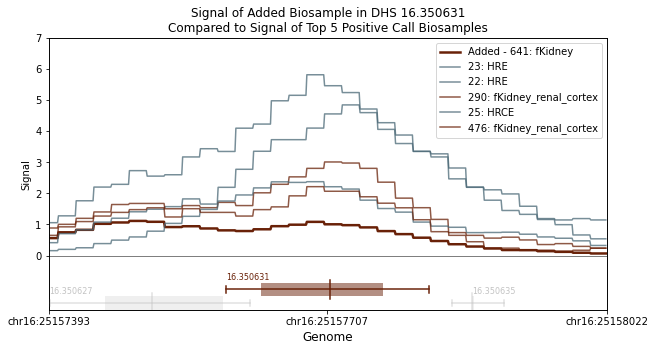

In [55]:
def added_call_plots(i, buffer=200, num_kp_to_plot=5):
    biosample_ind = added_biosample_inds[i]
    DHS_ind = added_DHS_inds[i]
    DHS_start = int(DHS_metadata.loc[DHS_ind]['start'])
    DHS_end = int(DHS_metadata.loc[DHS_ind]['end'])
    DHS_core_start = int(DHS_metadata.loc[DHS_ind]['core_start'])
    DHS_core_end = int(DHS_metadata.loc[DHS_ind]['core_end'])
    DHS_peak = int(DHS_metadata.loc[DHS_ind]['summit'])
    identifier = DHS_metadata.loc[DHS_ind]['identifier']
    DHS_top_comp_original = mixture_all_cycles_top_comp[0, DHS_ind]

    chrm = DHS_metadata.loc[DHS_ind]['seqname']
    recon_val = added_recon_all_cycles[0][i]

    #defining start and end for plot
    plt_start = DHS_start - buffer
    plt_end = DHS_end + buffer

    #known positives for DHS
    kp_biosamples = np.arange(n_biosamples)[cycle0_dhs_arr[:, DHS_ind]]

    #known positives for DHS sorted by max signal
    sorted_kp_biosamples = kp_biosamples[np.argsort(-DHS_max_signal_array[kp_biosamples, DHS_ind])]

    biosample_comp_counts = np.zeros(16, dtype=int)

    fig, axes = plt.subplots(nrows=1, figsize=(10,5))
    fig.patch.set_facecolor('white')

    plotted_biosamples = []
    max_signal_val = 0

    linestyles = ['solid', 'dotted', 'dashed', 'dashdot', (0, (3, 1, 1, 1, 1, 1))]

    #biosample of interest
    biosample_name = biosample_df.loc[biosample_ind]['Biosample name']
    plotted_biosamples.append('Added - ' + str(biosample_ind) + ': ' + biosample_name)
    agnum = biosample_df.loc[biosample_ind]['Altius Aggregation ID'][2:]
    ln = biosample_df.loc[biosample_ind]['Altius Library ID']
    if ln[-1].isalpha():
        ln = ln[:-1]
    filename = '/net/seq/data/aggregations/' + ln + '/aggregation-' + agnum + '/' + ln + '.75_20.normalized.GRCh38_no_alts.bw'
    bw_file = pyBigWig.open(filename)
    read_in_question = bw_file.values(chrm, 
                                      plt_start, 
                                      plt_end, 
                                      numpy=True)
    max_signal_val = np.nanmax([max_signal_val, np.nanmax(read_in_question)])
    biosample_top_comp_original = basis_all_cycles_top_comp[0, biosample_ind]
    c = color[biosample_top_comp_original]

    comp_count = biosample_comp_counts[biosample_top_comp_original]
    l = linestyles[comp_count]
    biosample_comp_counts[biosample_top_comp_original] += 1

    axes.plot(np.arange(plt_start, plt_end), read_in_question, c=c, linewidth=2.5) # c=c, linestyle=l


    for ind in range(num_kp_to_plot):
        kp_biosample_ind = sorted_kp_biosamples[ind]
        kp_biosample_name = biosample_df.loc[kp_biosample_ind]['Biosample name']
        plotted_biosamples.append(str(kp_biosample_ind) + ': ' + kp_biosample_name)
        kp_agnum = biosample_df.loc[kp_biosample_ind]['Altius Aggregation ID'][2:]
        kp_ln = biosample_df.loc[kp_biosample_ind]['Altius Library ID']
        if kp_ln[-1].isalpha():
            kp_ln = kp_ln[:-1]
        filename = '/net/seq/data/aggregations/' + kp_ln + '/aggregation-' + kp_agnum + '/' + kp_ln + '.75_20.normalized.GRCh38_no_alts.bw'
        bw_file = pyBigWig.open(filename)
        kp_read = bw_file.values(chrm, 
                                 plt_start, 
                                 plt_end, 
                                 numpy=True)
        max_signal_val = np.nanmax([max_signal_val, np.nanmax(kp_read)])
        kp_biosample_top_comp_original = basis_all_cycles_top_comp[0, kp_biosample_ind]
        c = color[kp_biosample_top_comp_original]

        comp_count = biosample_comp_counts[kp_biosample_top_comp_original]
    #     l = linestyles[comp_count]
    #     a = 0.75 - (comp_count * 0.15)
        a = 0.75
        biosample_comp_counts[kp_biosample_top_comp_original] += 1

        axes.plot(np.arange(plt_start, plt_end), kp_read, alpha=a, c=c) #linestyle=l, c=c

    ax_twin = axes.twinx()

    #DHS structure
    c = color[DHS_top_comp_original]

    adjustment = 0
    if DHS_core_end - DHS_core_start == 0:
        adjustment = 2

    dhs_bot = 0.05
    dhs_height = 0.05

    dhs_rect = patches.Rectangle((DHS_core_start, dhs_bot),
                                  DHS_core_end - DHS_core_start + adjustment, 
                                  dhs_height,
                                  facecolor=c,
                                  alpha=0.5)
    ax_twin.add_patch(dhs_rect)
    ax_twin.text(DHS_start, dhs_bot + dhs_height + 0.01, identifier, fontsize=8, c=c)

    #plotting range of DHS
    ax_twin.plot(np.arange(DHS_start, DHS_end + 1), 
                 np.ones(DHS_end - DHS_start + 1)*(dhs_height / 2 + dhs_bot),
                 c=c)
    ax_twin.plot([DHS_start, DHS_start], 
                 [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                 c=c)
    ax_twin.plot([DHS_end, DHS_end], 
                 [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                 c=c)
    ax_twin.plot([DHS_peak, DHS_peak], 
                 [dhs_bot-0.01, dhs_bot+dhs_height+0.01],
                 c=c)

    ###DHS to right
    dhs_bot = 0
    right_DHS_df = DHS_metadata.loc[[DHS_ind+1]]
    right_identifier = np.array(right_DHS_df['identifier'])[0]

    right_core_start = np.max([np.array(right_DHS_df['core_start']).astype(int)[0], 
                               np.array(right_DHS_df['start']).astype(int)[0]])
    right_core_end = np.min([np.array(right_DHS_df['core_end']).astype(int)[0], 
                             np.array(right_DHS_df['end']).astype(int)[0]])
    right_DHS_start = int(np.array(right_DHS_df['start']))
    right_DHS_end = int(np.array(right_DHS_df['end']))

    right_DHS_peak = np.array(right_DHS_df['summit']).astype(int)[0]
    right_DHS_top_comp_original = mixture_all_cycles_top_comp[0, DHS_ind+1]

    c = color[right_DHS_top_comp_original]
    adjustment = 0
    if right_core_end - right_core_start == 0:
        adjustment = 2
    right_dhs_rect = patches.Rectangle((right_core_start, dhs_bot),
                                        right_core_end - right_core_start + adjustment, 
                                        dhs_height,
                                        facecolor=c,
                                        alpha=0.25)
    ax_twin.add_patch(right_dhs_rect)
    if right_DHS_end < plt_end:
        ax_twin.text(right_core_end, dhs_bot + dhs_height + 0.01, right_identifier, fontsize=8, c=c)


    #plotting range of DHS
    ax_twin.plot(np.arange(right_DHS_start, right_DHS_end + 1), 
                 np.ones(right_DHS_end - right_DHS_start + 1)*(dhs_height / 2 + dhs_bot),
                 c=c,
                 alpha=0.5)
    ax_twin.plot([right_DHS_start, right_DHS_start], 
                 [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                 c=c,
                 alpha=0.5)
    ax_twin.plot([right_DHS_end, right_DHS_end], 
                 [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                 c=c,
                 alpha=0.5)
    ax_twin.plot([right_DHS_peak, right_DHS_peak], 
                 [dhs_bot-0.01, dhs_bot+dhs_height+0.01],
                 c=c,
                 alpha=0.5)


    ###DHS to left
    dhs_bot = 0
    left_DHS_df = DHS_metadata.loc[[DHS_ind-1]]
    left_identifier = np.array(left_DHS_df['identifier'])[0]

    left_core_start = np.max([np.array(left_DHS_df['core_start']).astype(int)[0], 
                               np.array(left_DHS_df['start']).astype(int)[0]])
    left_core_end = np.min([np.array(left_DHS_df['core_end']).astype(int)[0], 
                             np.array(left_DHS_df['end']).astype(int)[0]])
    left_DHS_start = int(np.array(left_DHS_df['start']))
    left_DHS_end = int(np.array(left_DHS_df['end']))
    left_DHS_peak = np.array(left_DHS_df['summit']).astype(int)[0]
    left_DHS_top_comp_original = mixture_all_cycles_top_comp[0, DHS_ind+1]

    c = color[left_DHS_top_comp_original]
    adjustment = 0
    if left_core_end - left_core_start == 0:
        adjustment = 2
    left_dhs_rect = patches.Rectangle((left_core_start, dhs_bot),
                                        left_core_end - left_core_start + adjustment, 
                                        dhs_height,
                                        facecolor=c,
                                        alpha=0.25)
    ax_twin.add_patch(left_dhs_rect)
    if left_DHS_start > plt_start:
        ax_twin.text(left_DHS_start, dhs_bot + dhs_height + 0.01, left_identifier, fontsize=8, c=c)


    #plotting range of DHS
    ax_twin.plot(np.arange(left_DHS_start, left_DHS_end + 1), 
                 np.ones(left_DHS_end - left_DHS_start + 1)*(dhs_height / 2 + dhs_bot),
                 c=c,
                 alpha=0.5)
    ax_twin.plot([left_DHS_start, left_DHS_start], 
                 [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                 c=c,
                 alpha=0.5)
    ax_twin.plot([left_DHS_end, left_DHS_end], 
                 [dhs_height / 4 + dhs_bot, 3 * dhs_height / 4 + dhs_bot],
                 c=c,
                 alpha=0.5)
    ax_twin.plot([left_DHS_peak, left_DHS_peak], 
                 [dhs_bot-0.01, dhs_bot+dhs_height+0.01],
                 c=c,
                 alpha=0.5)
    
    axes.plot([plt_start, plt_end], [0, 0], c='k', linewidth=0.5)

    ax_twin.set_ylim([0, 1])
    ax_twin.set_yticks([])
    axes.set_ylim([-max_signal_val*3/10, max_signal_val+max_signal_val/5])
    yticks = np.array(axes.get_yticks()).astype(int)
    yticks = yticks[yticks>=0]
    axes.set_yticks(yticks)
    axes.set_ylabel('Signal')
    axes.set_xlabel('Genome', fontsize=12)
    axes.set_xlim([plt_start, plt_end])
    axes.set_xticks([plt_start, int((plt_end+plt_start)/2), plt_end])
    axes.set_xticklabels([chrm + ':' + str(plt_start), chrm + ':' + str(int((plt_end+plt_start)/2)), chrm + ':' + str(plt_end)])
    axes.legend(plotted_biosamples)
    title = 'Signal of Added Biosample in DHS %s\nCompared to Signal of Top 5 Positive Call Biosamples' %(identifier)
    axes.set_title(title)
    today = date.today()
    plt.savefig('/home/ctrader/figures/NMF/DHS/quality_of_NMF_recon_threshold_flip_01thresh_peak_added_analysis/'+title.replace(' ', '_') + '_CT' + today.strftime("%Y%m%d") + '.png')
    print(title)
    plt.show()
    
for i in range(20, 30):
    added_call_plots(i)

In [65]:
basis_all_cycles[0, 455, :]

array([0.        , 0.        , 0.        , 0.43097052, 0.4217055 ,
       0.        , 0.        , 1.1886379 , 0.7827357 , 0.7301697 ,
       0.18721822, 9.001186  , 0.        , 1.1012841 , 1.066218  ,
       0.        ], dtype=float32)

In [69]:
np.argmax(basis_all_cycles[0])//16

651

In [74]:
comps_for_heatmap

['Tissue invariant',
 'Stromal A',
 'Primitive / embryonic',
 'Stromal B',
 'Lymphoid',
 'Renal / cancer',
 'Placental / trophoblast',
 'Neural',
 'Cardiac',
 'Organ devel. / renal',
 'Pulmonary devel.',
 'Musculoskeletal',
 'Digestive',
 'Vascular / endothelial',
 'Myeloid / erythroid',
 'Cancer / epithelial']

In [70]:
basis_all_cycles[0, 651, :]

array([ 0.        ,  0.        ,  0.        ,  0.6921187 ,  0.        ,
        0.15693307, 14.680075  ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ,  0.        ,  0.        ,  0.16388491,
        0.        ], dtype=float32)

In [73]:
np.where(added_biosample_inds==455)

(array([    0,     1,     2,     5,     9,    11,    13,    15,    18,
           24,    27,    34,    36,    38,    44,    47,    53,    55,
           77,   104,   105,   115,   142,   147,   168,   172,   175,
          183,   187,   216,   225,   239,   257,   266,   270,   272,
          273,   283,   285,   299,   312,   332,   340,   377,   398,
          459,   498,   505,   528,   547,   573,   604,   643,   659,
          675,   677,   688,   692,   736,   777,   801,   806,   826,
          844,   869,   988,  1026,  1029,  1046,  1112,  1141,  1198,
         1211,  1221,  1258,  1297,  1298,  1309,  1327,  1419,  1528,
         1599,  1640,  1648,  1650,  1690,  1706,  1739,  1788,  1840,
         1843,  1862,  1903,  1913,  1951,  1994,  2027,  2048,  2166,
         2183,  2322,  2359,  2369,  2390,  2500,  2570,  2593,  2817,
         2844,  3034,  3072,  3127,  3177,  3219,  3287,  3312,  3335,
         3449,  3472,  3504,  3599,  3713,  3977,  3985,  4117,  4159,
      